# LSTM neuronska mreža za XAUUSD — trejdovi sa odnosom rizik:profit **1:2**

Za svaku sveću mreža daje verovatnoće **tri ishoda** (kao u referentnom XGBoost notebook-u):

* **0** — nema trejda (ni long ni short ne dostiže +2R pre −1R)
* **1** — **short** dostiže TP (+2R) pre SL (−1R)
* **2** — **long** dostiže TP (+2R) pre SL (−1R)

Trejd: ulaz na otvaranju sledeće sveće, **SL = 1R**, **TP = 2R** (R = `SL_ATR_MULT` × ATR14), vremenski limit `HORIZON` sveća.
Podaci su isključivo tvoji CSV fajlovi. **Train: 2016 → 2025, test: 2026.**

In [200]:
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ===================== PODESAVANJA =====================
TIMEFRAME   = "1h"                                   # "1h" ili "1d"
_data_env = os.environ.get("XAU_DATA_DIR")
if _data_env:
    DATA_DIR = Path(_data_env).expanduser()
else:
    _data_candidates = [Path("./dataset"), Path("./code/dataset")]
    DATA_DIR = next(
        (p for p in _data_candidates if (p / "XAUUSD60.csv").exists()),
        _data_candidates[0]
    )  # automatski nalazi dataset iz root ili code foldera
TRAIN_START = pd.Timestamp("2016-01-03")
TEST_START  = pd.Timestamp("2026-01-03")               # sve pre = train, od ovog datuma = test
BACKCANDLES = {"1h": 43, "1d": 25}[TIMEFRAME]          # koliko poslednjih sveca LSTM vidi
SPREAD_USD  = 0.25                                     # trosak (spread) po round-trip-u, USD/oz
SEED        = 42

# ----- trejd 1:2 -----
RR            = 3      # TP = RR * R
SL_ATR_MULT   = 1.0      # R (rizik po trejdu) = SL_ATR_MULT * ATR14  (u USD po unci)
HORIZON       = {"1h": 24, "1d": 10}[TIMEFRAME]   # max trajanje trejda u svecama (posle toga izlaz po close)
RISK_PCT      = 1.0      # % kapitala koji se riskira po trejdu (samo za racun prinosa)

# ★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
# ★★★  TREND — OVDE MENJAS (smer trenda po pomeraju cene)           ★★★
# ★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
TREND_PIPS       = 250     # pomeraj od ovoliko pipsa GORE = trend LONG, DOLE = trend SHORT
PIP_SIZE_USD     = 0.10    # 1 pip zlata u USD (0.10 -> 250 pipsa = $25; ako tvoj broker racuna 1 pip = $0.01, stavi 0.01)
TREND_LOOKBACK   = {"1h": 43, "1d": 7}[TIMEFRAME]   # koliko poslednjih sveca se gleda unazad
USE_TREND_FILTER = True    # True = trguj samo u smeru trenda (neutralan = bez trejda); False = filter iskljucen
TREND_EMA_LEN    = 20     # trend vazi samo ako je cena sa ISTE strane EMA(200) kao pomeraj (0 = iskljuceno)
AUTO_SELECT_TREND = True   # True: TREND_PIPS / TREND_LOOKBACK / TREND_EMA_LEN se biraju automatski SAMO na train godinama 2016-2025 (sekcija 11); False: vrede ovde upisane vrednosti
MIN_TREND_TRADES = {"1h": 500, "1d": 200}[TIMEFRAME]   # minimalan broj trejdova da kandidat uopste ulazi u auto-izbor
META_QUANTILE    = 0.50    # meta model: uzima se samo bolja polovina trend-setup-a (0.50); 0.70 = samo najboljih 30%
# ★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
print("Timeframe:", TIMEFRAME, "| backcandles:", BACKCANDLES, "| podaci iz:", DATA_DIR.resolve())

Timeframe: 1h | backcandles: 43 | podaci iz: /Users/djordjeradosavljevic/Downloads/fax/diplomski/code/dataset


## 1. Učitavanje podataka (tvoji CSV fajlovi)

In [201]:
def find_file(data_dir, key):
    """Nalazi fajl po delu imena (ignorise razmake, '-', '_' i velika slova)."""
    norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
    for p in sorted(Path(data_dir).glob("*.csv")):
        if norm(key) in norm(p.name):
            return p
    raise FileNotFoundError(f"Ne nalazim fajl koji sadrzi '{key}' u {data_dir}")

def load_mt5(path):
    """MT5 export: tab-separated, bez header-a: Date Open High Low Close Volume."""
    df = pd.read_csv(path, sep="\t", header=None, usecols=range(5),
                     names=["Date", "Open", "High", "Low", "Close"])
    df["Date"] = pd.to_datetime(df["Date"], format="mixed")
    df = df.set_index("Date").sort_index()
    return df[~df.index.duplicated(keep="last")]

def load_investing(path):
    """Investing.com export -> Close serija (kolona Price)."""
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
    s = df.set_index("Date")["Price"].sort_index()
    if s.dtype == object:
        s = s.str.replace(",", "").astype(float)
    return s[~s.index.duplicated(keep="last")].astype(float)

def load_fred(path, monthly=False):
    df = pd.read_csv(path)
    df.columns = ["Date", "Value"]
    df["Date"] = pd.to_datetime(df["Date"])
    s = df.set_index("Date")["Value"].sort_index().astype(float)
    if monthly:
        s.index = s.index.to_period("M")
    return s

In [202]:
TF_FILES = {"1h": "XAUUSD60.csv", "1d": "XAUUSD1440.csv"}
gold = load_mt5(DATA_DIR / TF_FILES[TIMEFRAME])
print("Zlato:", gold.shape, "|", gold.index.min(), "->", gold.index.max())
gold.head(10)

,Open,High,Low,Close
Date,,,,
2010-02-15 01:00:00,1094.460,1094.554,1091.851,1092.724
2010-02-15 02:00:00,1092.854,1093.995,1092.832,1093.565
2010-02-15 03:00:00,1093.588,1095.154,1093.238,1093.803
2010-02-15 04:00:00,1093.807,1093.897,1092.577,1092.707
2010-02-15 05:00:00,1092.871,1093.104,1091.260,1091.294
2010-02-15 06:00:00,1091.362,1092.627,1091.194,1092.120
2010-02-15 07:00:00,1092.212,1094.526,1091.358,1094.353
2010-02-15 08:00:00,1094.379,1096.376,1093.370,1093.843
2010-02-15 09:00:00,1093.745,1098.570,1093.457,1098.035


In [203]:
gold.tail(5)

,Open,High,Low,Close
Date,,,,
2026-11-04 03:00:00,3935.085,3941.855,3926.605,3934.085
2026-11-04 04:00:00,3934.085,3957.464,3932.689,3951.735
2026-11-04 05:00:00,3951.735,4009.454,3945.545,3997.535
2026-11-04 06:00:00,3997.604,4027.914,3995.944,4026.964
2026-11-04 07:00:00,4027.164,4029.004,4014.535,4022.235


In [204]:
dxy   = load_investing(find_file(DATA_DIR, "us_dollar_index"))
vix   = load_investing(find_file(DATA_DIR, "volatility_index"))
wti   = load_investing(find_file(DATA_DIR, "wti"))
us10y = load_fred(find_file(DATA_DIR, "US10YN"))
btc   = load_mt5(find_file(DATA_DIR, "BTCUSD1440"))["Close"]
cpi   = load_fred(find_file(DATA_DIR, "CPI"), monthly=True)
ppi   = load_fred(find_file(DATA_DIR, "PPI"), monthly=True)
nfp   = load_fred(find_file(DATA_DIR, "NFP"), monthly=True)

pd.DataFrame({
    "izvor": ["DXY", "VIX", "WTI", "US10Y", "BTC (dnevni)", "CPI", "PPI", "NFP"],
    "od":    [str(s.index.min())[:10] for s in (dxy, vix, wti, us10y, btc, cpi, ppi, nfp)],
    "do":    [str(s.index.max())[:10] for s in (dxy, vix, wti, us10y, btc, cpi, ppi, nfp)],
    "redova":[len(s) for s in (dxy, vix, wti, us10y, btc, cpi, ppi, nfp)],
})

,izvor,od,do,redova
0,DXY,2016-01-04,2026-11-05,2824
1,VIX,2016-01-04,2026-11-05,2774
2,WTI,2026-10-05,2026-11-05,26
3,US10Y,2016-01-04,2026-11-02,2826
4,BTC (dnevni),2017-05-23,2026-11-04,3277
5,CPI,2016-01,2026-09,129
6,PPI,2016-01,2026-09,129
7,NFP,2016-01,2026-09,129


## 2. Tehnički indikatori i feature-i

Parametri indikatora su u rečniku `TA` — **ovde menjaš svoje vrednosti** (RSI, MACD, EMA, SMA).
Svi feature-i su normalizovani (odnosi / procenti), da mreža ne uči apsolutni nivo cene.

In [205]:
# ---- parametri tehnickih indikatora (zameni svojim vrednostima) ----
TA = dict(
    rsi_len   = 14,
    macd      = (12, 26, 9),     # fast, slow, signal
    ema_lens  = (20, 50, 100),   # brza, srednja, spora
    sma_lens  = (50, 200),
    boll_len  = 20,
    atr_len   = 16,
)

def rsi(close, n):
    d = close.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn.replace(0, np.nan))

def technical_features(x, ta=TA):
    f = pd.DataFrame(index=x.index)
    c = x["Close"]

    f["RSI"] = rsi(c, ta["rsi_len"])

    fast, slow, sig = ta["macd"]
    macd_line = c.ewm(span=fast, adjust=False).mean() - c.ewm(span=slow, adjust=False).mean()
    f["MACD_line"] = macd_line / c
    f["MACD_hist"] = (macd_line - macd_line.ewm(span=sig, adjust=False).mean()) / c

    emas = {n: c.ewm(span=n, adjust=False).mean() for n in ta["ema_lens"]}
    for n, e in emas.items():
        f[f"EMA{n}_ratio"] = c / e - 1
    ns = sorted(emas)
    f[f"EMA{ns[0]}_vs_EMA{ns[-1]}"] = emas[ns[0]] / emas[ns[-1]] - 1

    smas = {n: c.rolling(n).mean() for n in ta["sma_lens"]}
    for n, s in smas.items():
        f[f"SMA{n}_ratio"] = c / s - 1
    ns = sorted(smas)
    f[f"SMA{ns[0]}_vs_SMA{ns[-1]}"] = smas[ns[0]] / smas[ns[-1]] - 1

    mid, sd = c.rolling(ta["boll_len"]).mean(), c.rolling(ta["boll_len"]).std()
    f["BOLL_pos"] = (c - mid) / (2 * sd.replace(0, np.nan))

    tr = pd.concat([x["High"] - x["Low"], (x["High"] - c.shift(1)).abs(),
                    (x["Low"] - c.shift(1)).abs()], axis=1).max(axis=1)
    f["ATR_norm"] = tr.rolling(ta["atr_len"]).mean() / c

    for h in (1, 3, 6, 12, 24):
        f[f"ret_{h}"] = c.pct_change(h)
    r1 = c.pct_change()
    for w in (12, 24, 72):
        f[f"vol_{w}"] = r1.rolling(w).std()
    f["dow"] = x.index.dayofweek
    return f

tech = technical_features(gold)
tech.tail()

,RSI,MACD_line,MACD_hist,EMA20_ratio,EMA50_ratio,EMA100_ratio,EMA20_vs_EMA100,SMA50_ratio,SMA200_ratio,SMA50_vs_SMA200,BOLL_pos,ATR_norm,ret_1,ret_3,ret_6,ret_12,ret_24,vol_12,vol_24,vol_72,dow
Date,,,,,,,,,,,,,,,,,,,,,
2026-11-04 03:00:00,51.311857,0.000423,0.000307,0.000672,-0.000439,-0.005599,-0.006266,0.001928,-0.014841,-0.016737,0.217602,0.004588,-0.000254,0.000659,0.003302,-0.002606,-0.002879,0.002138,0.003052,0.003020,2
2026-11-04 04:00:00,57.988942,0.000772,0.000525,0.004668,0.003886,-0.001115,-0.005755,0.006167,-0.010262,-0.016329,0.692305,0.004839,0.004486,0.001289,0.005622,0.003973,0.006520,0.002436,0.003014,0.003070,2
2026-11-04 05:00:00,69.628479,0.001940,0.001357,0.014735,0.014903,0.010253,-0.004417,0.017370,0.001286,-0.015809,1.535221,0.005242,0.011590,0.015870,0.015091,0.017812,0.018897,0.003931,0.003786,0.003368,2
2026-11-04 06:00:00,74.514543,0.003402,0.002258,0.020048,0.021478,0.017334,-0.002661,0.024169,0.008735,-0.015070,1.528348,0.005030,0.007362,0.023609,0.024283,0.024016,0.027723,0.004279,0.003987,0.003466,2
2026-11-04 07:00:00,72.496239,0.004431,0.002629,0.017025,0.019468,0.015814,-0.001190,0.022341,0.007593,-0.014426,1.170519,0.004914,-0.001174,0.017840,0.019152,0.024023,0.028296,0.004279,0.003971,0.003467,2


In [206]:
def intraday_features(x):
    """Pozicija u tekucem danu + sat/sesije (samo za 1h)."""
    f = pd.DataFrame(index=x.index)
    day = pd.Index(x.index.date)
    c = x["Close"]
    hi = x["High"].groupby(day).cummax()
    lo = x["Low"].groupby(day).cummin()
    f["day_range_pos"] = (c - lo) / (hi - lo).replace(0, np.nan)
    f["dist_day_high"] = (hi - c) / c
    f["dist_day_low"] = (c - lo) / c
    daily_close = c.groupby(day).last()
    daily_close.index = pd.to_datetime(daily_close.index)
    f["gap_vs_prev_close"] = c / x.index.normalize().map(daily_close.shift(1)).values - 1
    h = x.index.hour
    f["hour_sin"] = np.sin(2 * np.pi * h / 24)
    f["hour_cos"] = np.cos(2 * np.pi * h / 24)
    f["sess_asia"]   = ((h >= 0)  & (h <= 7)).astype(int)
    f["sess_london"] = ((h >= 8)  & (h <= 12)).astype(int)
    f["sess_ny"]     = ((h >= 13) & (h <= 20)).astype(int)
    return f

def daily_series_features(s, prefix):
    d = pd.DataFrame(index=s.index)
    d[f"{prefix}_ret1d"] = s.pct_change()
    d[f"{prefix}_ret5d"] = s.pct_change(5)
    m, sd = s.rolling(20).mean(), s.rolling(20).std()
    d[f"{prefix}_z20"] = (s - m) / sd.replace(0, np.nan)
    d[f"{prefix}_sma20_ratio"] = s / m - 1
    return d

def attach_daily(bar_index, feat):
    """
    Dnevni podatak dana D postaje poznat tek na kraju dana D:
    razvuci na kalendarske dane (ffill), pomeri 1 dan unapred -> bar na datumu D vidi dane <= D-1.
    """
    end = max(feat.index.max(), bar_index.max().normalize())
    cal = feat.reindex(pd.date_range(feat.index.min(), end, freq="D")).ffill().shift(1)
    out = cal.reindex(bar_index.normalize())
    out.index = bar_index
    return out

def monthly_features(s, prefix, end):
    """MoM + razlika; kasnjenje 2 meseca (objava u M+1, konzervativno M+2). Rupa u izvoru se interpolira."""
    s = s.interpolate(limit_area="inside")
    d = pd.DataFrame({f"{prefix}_mom": s.pct_change(), f"{prefix}_diff": s.diff()})
    d = d.reindex(pd.period_range(d.index.min(), max(d.index.max(), end), freq="M"))
    return d.shift(2)

def attach_monthly(bar_index, feat):
    out = feat.reindex(bar_index.to_period("M"))
    out.index = bar_index
    return out

In [207]:
# Formiranje feature matrice bez prepisivanja originalnih podataka.
# Serije koje nemaju istoriju od TRAIN_START automatski se preskacu.
parts = [tech]

if TIMEFRAME == "1h":
    parts.append(intraday_features(gold))

    # Prethodna zavrsena dnevna sveca zlata
    xd = load_mt5(DATA_DIR / TF_FILES["1d"])["Close"]
    fd = pd.DataFrame(index=xd.index)
    fd["xau1d_ret"] = xd.pct_change()
    fd["xau1d_ret5"] = xd.pct_change(5)
    fd["xau1d_sma20_ratio"] = xd / xd.rolling(20).mean() - 1
    fd["xau1d_sma50_ratio"] = xd / xd.rolling(50).mean() - 1
    fd["xau1d_vol20"] = xd.pct_change().rolling(20).std()
    fd["xau1d_hi20_dist"] = xd / xd.rolling(20).max() - 1
    parts.append(attach_daily(gold.index, fd))

# Dnevni eksterni faktori.
# Ne dodajemo seriju ako pocinje posle TRAIN_START; time se ne gubi cela istorija
# zbog jednog kratkog ili nepotpunog CSV fajla.
external_daily = {
    "dxy": dxy,
    "vix": vix,
    "wti": wti,
    "us10y": us10y,
    "btc": btc,
}
used_external = []
skipped_external = []

def first_timestamp(index):
    value = index.min()
    if isinstance(value, pd.Period):
        value = value.to_timestamp()
    return pd.Timestamp(value)

def last_timestamp(index):
    value = index.max()
    if isinstance(value, pd.Period):
        value = value.to_timestamp(how="end")
    return pd.Timestamp(value)

# Dozvoljavamo malu razliku izmedju 01.01.2016 i prvog radnog dana (npr. 04.01.).
min_allowed_start = TRAIN_START + pd.Timedelta(days=31)

for name, s in external_daily.items():
    first, last = first_timestamp(s.index), last_timestamp(s.index)
    if last < TRAIN_START or first > min_allowed_start:
        skipped_external.append((name, str(first), str(last)))
        continue
    parts.append(attach_daily(gold.index, daily_series_features(s, name)))
    used_external.append(name)

# Mesecni makro faktori.
for name, s in {"cpi": cpi, "ppi": ppi, "nfp": nfp}.items():
    first, last = first_timestamp(s.index), last_timestamp(s.index)
    if last < TRAIN_START or first > min_allowed_start:
        skipped_external.append((name, str(first), str(last)))
        continue
    parts.append(attach_monthly(gold.index, monthly_features(s, name, gold.index.max().to_period("M"))))
    used_external.append(name)

features = pd.concat(parts, axis=1)

# BTC nije postojao pre 2017; neutralna vrednost je eksplicitna odluka.
btc_cols = [c for c in features.columns if c.startswith("btc_")]
if btc_cols:
    features[btc_cols] = features[btc_cols].fillna(0.0)

print("Korisceni eksterni faktori:", used_external)
print("Preskoceni zbog nedovoljne istorije:", skipped_external)
print("FEATURES:", features.shape, "|", features.index.min(), "->", features.index.max())


Korisceni eksterni faktori: ['dxy', 'vix', 'us10y', 'cpi', 'ppi', 'nfp']
Preskoceni zbog nedovoljne istorije: [('wti', '2026-10-05 00:00:00', '2026-11-05 00:00:00'), ('btc', '2017-05-23 00:00:00', '2026-11-04 00:00:00')]
FEATURES: (100000, 54) | 2010-02-15 01:00:00 -> 2026-11-04 07:00:00


## 3. Trejd 1:2 i target (triple barrier)

Za **svaku** sveću `t` simuliramo dva hipotetička trejda (long i short):

* ulaz = otvaranje sveće `t+1`
* **R** = `SL_ATR_MULT` × ATR14 (rizik u USD po unci), **SL = ulaz ∓ 1R**, **TP = ulaz ± 2R**
* ako sveća dodirne i SL i TP, računa se **SL** (konzervativno)
* ako ništa nije pogođeno u `HORIZON` sveća → izlaz po zatvaranju poslednje sveće (rezultat između −1R i +2R)

Target: **2** = long pogađa TP pre SL, **1** = short pogađa TP pre SL, **0** = ni jedno.

> Break-even: sa odnosom 1:2 trejd je isplativ ako **win rate > 33.3%** (pre troškova).
> Nasumičan ulaz u “fer” tržištu pogađa TP pre SL otprilike u 1/3 slučajeva — to je osnova sa kojom se mreža poredi.

In [208]:
true_range = pd.concat([gold["High"] - gold["Low"],
                        (gold["High"] - gold["Close"].shift(1)).abs(),
                        (gold["Low"] - gold["Close"].shift(1)).abs()], axis=1).max(axis=1)
atr_usd = true_range.rolling(14).mean()                     # ATR14 u USD po unci

def triple_barrier(ohlc, atr, sl_mult, rr, horizon):
    o, h, l, c = (ohlc[k].values.astype(float) for k in ("Open", "High", "Low", "Close"))
    n = len(ohlc)
    m = n - horizon                                         # t = 0..m-1 imaju ceo prozor t+1 .. t+horizon
    Hw = sliding_window_view(h, horizon)[1:m + 1]           # (m, horizon): high sveca t+1 .. t+horizon
    Lw = sliding_window_view(l, horizon)[1:m + 1]
    c_last = c[horizon:horizon + m]                         # close poslednje svece u prozoru
    e = o[1:m + 1]                                          # ulaz: otvaranje sledece svece
    R = atr.values[:m] * sl_mult                            # rizik 1R u USD po unci
    big = horizon + 1
    out = pd.DataFrame(index=ohlc.index[:m])
    out["entry"], out["R"] = e, R
    for side, d in (("long", 1), ("short", -1)):
        tp, sl = e + d * rr * R, e - d * R
        hit_tp = (Hw >= tp[:, None]) if d == 1 else (Lw <= tp[:, None])
        hit_sl = (Lw <= sl[:, None]) if d == 1 else (Hw >= sl[:, None])
        i_tp = np.where(hit_tp.any(1), hit_tp.argmax(1), big)
        i_sl = np.where(hit_sl.any(1), hit_sl.argmax(1), big)
        win  = i_tp < i_sl                                  # ista sveca = SL (konzervativno)
        loss = (i_sl < big) & (i_sl <= i_tp)
        res  = np.where(win, rr, np.where(loss, -1.0, d * (c_last - e) / R))
        ex   = np.where(win, i_tp, np.where(loss, i_sl, horizon - 1))
        out[f"{side}_win"]  = win
        out[f"{side}_res"]  = res                           # rezultat trejda u R (bruto)
        out[f"{side}_exit"] = np.arange(m) + 1 + ex         # pozicija svece u kojoj se trejd zatvara
    out["label"] = np.select([out["long_win"], out["short_win"]], [2, 1], default=0).astype(float)
    out.loc[out["R"].isna(), "label"] = np.nan
    return out

labels = triple_barrier(gold, atr_usd, SL_ATR_MULT, RR, HORIZON)
labels.tail()

,entry,R,long_win,long_res,long_exit,short_win,short_res,short_exit,label
Date,,,,,,,,,
2026-11-03 02:00:00,3945.328,16.823143,False,-1.0,99972,False,-1.0,99982,0.0
2026-11-03 03:00:00,3926.103,17.790286,False,-1.0,99976,False,-1.0,99982,0.0
2026-11-03 04:00:00,3923.404,14.588643,False,-1.0,99976,False,-1.0,99982,0.0
2026-11-03 05:00:00,3918.285,13.218000,False,-1.0,99977,False,-1.0,99981,0.0
2026-11-03 06:00:00,3911.555,13.230929,False,-1.0,99977,False,-1.0,99981,0.0


In [209]:
# print(type(data))
# print(data.columns.tolist())
# print("Broj Target kolona:", (data.columns == "Target").sum())
# print(type(data["Target"]))
# print(data["Target"].head())


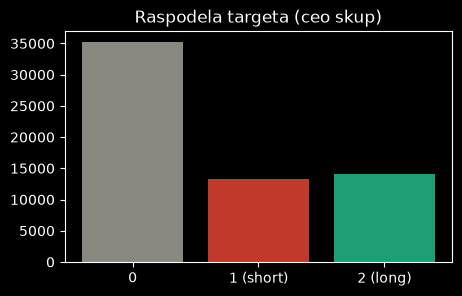

In [210]:
# Pravljenje konacnog skupa uvek iz originalne feature matrice.
# Ova kopija sprecava da ponovno pokretanje celije trajno skrati data.
data = features.copy()
data = data.loc[:, data.columns != "Target"]

data = data.join(labels["label"].rename("Target"), how="left")
data = data[data.index >= TRAIN_START]
data = data.replace([np.inf, -np.inf], np.nan)

# Target i feature-i moraju postojati za isti red.
data = data.dropna(axis=0, how="any").copy()
if data.empty:
    raise ValueError(
        "Nema validnih redova nakon filtriranja. Proveri opsege CSV fajlova "
        "i listu preskocenih eksternih faktora iz prethodne celije."
    )

data["Target"] = data["Target"].astype(int)
lab = labels.reindex(data.index)

names = [
    "0: bez trejda",
    "1: short pogadja TP",
    "2: long pogadja TP",
]
counts = (
    data["Target"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
    .sort_index()
)
share = counts / counts.sum()

print("DATA:", data.shape, "|", data.index.min(), "->", data.index.max())
print("Target kolone:", (data.columns == "Target").sum())
print(pd.DataFrame({"broj": counts.values, "udeo": share.round(3).values}, index=names))
print(
    f"\nBreak-even win rate za RR 1:{RR:.0f} = {1 / (1 + RR):.1%}  | "
    f"prosecan R u USD: {lab['R'].mean():.2f}  | "
    f"spread u R: {SPREAD_USD / lab['R'].mean():.3f}"
)

plt.figure(figsize=(5, 3))
plt.bar(["0", "1 (short)", "2 (long)"], counts.values,
        color=["#888780", "#C0392B", "#1D9E75"])
plt.title("Raspodela targeta (ceo skup)")
plt.show()


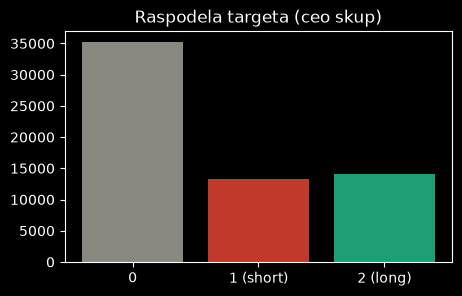

In [211]:



data = (
    data[data.index >= TRAIN_START]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

data["Target"] = data["Target"].astype(int)

lab = labels.reindex(data.index)

names = [
    "0: bez trejda",
    "1: short pogadja TP",
    "2: long pogadja TP"
]

counts = (
    data["Target"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
    .sort_index()
)

share = counts / counts.sum()

print("Redova:", len(data), "|", data.index.min(), "->", data.index.max())

print(pd.DataFrame(
    {
        "broj": counts.values,
        "udeo": share.round(3).values
    },
    index=names
))

print(
    f"\nBreak-even win rate za RR 1:{RR:.0f} = {1 / (1 + RR):.1%}  | "
    f"prosecan R u USD: {lab['R'].mean():.2f}  | "
    f"spread u R: {SPREAD_USD / lab['R'].mean():.3f}"
)

plt.figure(figsize=(5, 3))
plt.bar(
    ["0", "1 (short)", "2 (long)"],
    counts.values,
    color=["#888780", "#C0392B", "#1D9E75"]
)
plt.title("Raspodela targeta (ceo skup)")
plt.show()


In [212]:
# data = data.join(labels[["label"]]).rename(columns={"label": "Target"})
# data = data[data.index >= TRAIN_START].replace([np.inf, -np.inf], np.nan).dropna()
# data["Target"] = data["Target"].astype(int)
# lab = labels.reindex(data.index)                              # detalji trejdova poravnati sa data
#
# names = ["0: bez trejda", "1: short pogadja TP", "2: long pogadja TP"]
# counts = data["Target"].value_counts().sort_index()
# share = counts / counts.sum()
# print("Redova:", len(data), "|", data.index.min(), "->", data.index.max())
# print(pd.DataFrame({"broj": counts.values, "udeo": share.round(3).values}, index=names))
# print(f"\nBreak-even win rate za RR 1:{RR:.0f} = {1 / (1 + RR):.1%}  |  "
#       f"prosecan R u USD: {lab['R'].mean():.2f}  |  spread u R: {SPREAD_USD / lab['R'].mean():.3f}")
#
# plt.figure(figsize=(5, 3))
# plt.bar(["0", "1 (short)", "2 (long)"], counts.values, color=["#888780", "#C0392B", "#1D9E75"])
# plt.title("Raspodela targeta (ceo skup)"); plt.show()

## 4. Podela na train / test (po datumu)

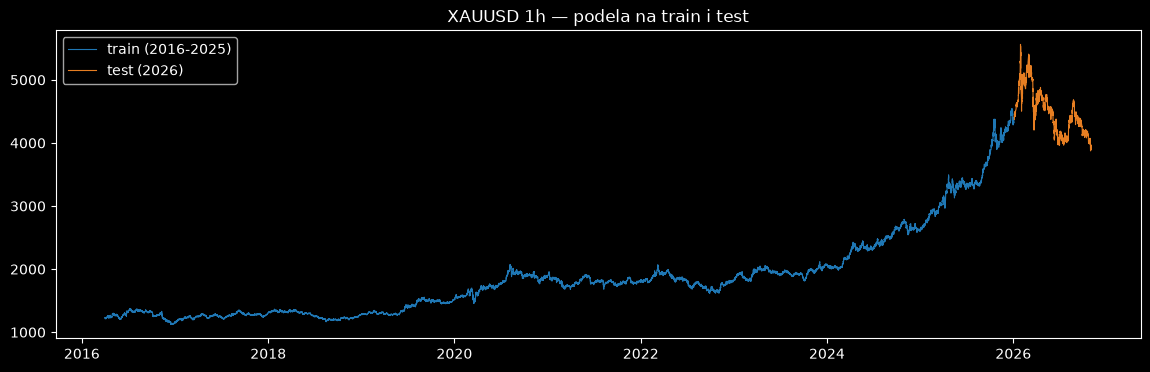

In [213]:
train_mask = data.index < TEST_START
print("TRAIN:", data.index[train_mask].min(), "->", data.index[train_mask].max(), "|", train_mask.sum(), "sveca")
print("TEST :", data.index[~train_mask].min(), "->", data.index[~train_mask].max(), "|", (~train_mask).sum(), "sveca")
print("Udeo klasa 0/1/2 u train:", data.loc[train_mask, "Target"].value_counts(normalize=True).sort_index().round(3).tolist())
print("Udeo klasa 0/1/2 u test :", data.loc[~train_mask, "Target"].value_counts(normalize=True).sort_index().round(3).tolist())

close_plot = gold["Close"].reindex(data.index)
plt.figure(figsize=(14, 4))
plt.plot(close_plot[train_mask], color="#1F77B4", lw=0.8, label="train (2016-2025)")
plt.plot(close_plot[~train_mask], color="#E67E22", lw=0.8, label="test (2026)")
plt.title(f"XAUUSD {TIMEFRAME} — podela na train i test"); plt.legend(); plt.show()

In [214]:
print("DATA:", data.index.min(), "->", data.index.max())
print("TEST_START:", TEST_START)
print("Broj train redova:", (data.index < TEST_START).sum())
print("Broj test redova:", (data.index >= TEST_START).sum())


DATA: 2016-04-01 00:00:00 -> 2026-11-03 06:00:00
TEST_START: 2026-01-03 00:00:00
Broj train redova: 57720
Broj test redova: 4937


## 5. Skaliranje (fit samo na train)

In [215]:
from sklearn.preprocessing import StandardScaler

# Maska se pravi tek nakon sto je data konacno formiran.
train_mask = data.index < TEST_START
feature_cols = [c for c in data.columns if c != "Target"]

if train_mask.sum() == 0:
    raise ValueError(
        f"Nema train redova: DATA={data.index.min()} -> {data.index.max()}, "
        f"TEST_START={TEST_START}."
    )
if (~train_mask).sum() == 0:
    raise ValueError(
        f"Nema test redova: DATA={data.index.min()} -> {data.index.max()}, "
        f"TEST_START={TEST_START}."
    )

X_fit = data.loc[train_mask, feature_cols]
if X_fit.isna().any().any():
    bad = X_fit.columns[X_fit.isna().any()].tolist()
    raise ValueError(f"NaN u train feature-ima: {bad}")

scaler = StandardScaler().fit(X_fit)
data_scaled = np.clip(scaler.transform(data[feature_cols]), -5, 5).astype(np.float32)
y_all = data["Target"].to_numpy(dtype=int)
times = data.index

print("Train redova:", train_mask.sum())
print("Test redova:", (~train_mask).sum())
print("Feature matrica:", data_scaled.shape)


Train redova: 57720
Test redova: 4937
Feature matrica: (62657, 54)


## 6. Sekvence (backcandles)

In [216]:
n_feat = data_scaled.shape[1]
windows = sliding_window_view(data_scaled, (BACKCANDLES, n_feat))[:, 0]   # (n - B + 1, B, p)
end_idx = np.arange(BACKCANDLES - 1, len(data_scaled))
y_seq, t_seq = y_all[end_idx], times[end_idx]
print("windows:", windows.shape, "| y:", y_seq.shape)

windows: (62615, 43, 54) | y: (62615,)


In [217]:
tr_mask_seq = t_seq < TEST_START
tr_pos = np.where(tr_mask_seq)[0]
te_pos = np.where(~tr_mask_seq)[0]

tr_pos = tr_pos[:-HORIZON]                              # embargo: target gleda HORIZON sveca unapred
n_val = max(int(len(tr_pos) * 0.10), 50)                # poslednjih 10% treninga = validacija
val_pos = tr_pos[-n_val:]
fit_pos = tr_pos[:-(n_val + max(BACKCANDLES, HORIZON))]

X_train, y_train = windows[fit_pos].astype(np.float32), y_seq[fit_pos]
X_val,   y_val   = windows[val_pos].astype(np.float32), y_seq[val_pos]
X_test,  y_test  = windows[te_pos].astype(np.float32),  y_seq[te_pos]
train_index, val_index, test_index = t_seq[fit_pos], t_seq[val_pos], t_seq[te_pos]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "| y_val  :", y_val.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)
print("Test period:", test_index[0], "->", test_index[-1])

X_train: (51846, 43, 54) | y_train: (51846,)
X_val  : (5765, 43, 54) | y_val  : (5765,)
X_test : (4937, 43, 54) | y_test : (4937,)
Test period: 2026-01-04 23:00:00 -> 2026-11-03 06:00:00


## 7. LSTM model (3 klase, softmax)

In [218]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(SEED)
UNITS = {"1h": 66, "1d": 32}[TIMEFRAME]

lstm_input = Input(shape=(BACKCANDLES, n_feat), name="lstm_input")
x = LSTM(UNITS, name="lstm_layer")(lstm_input)
x = Dropout(0.30)(x)
x = Dense(32, activation="relu", name="dense_32")(x)
x = Dropout(0.20)(x)
output = Dense(3, activation="softmax", name="output")(x)     # P(klasa 0), P(klasa 1 = short), P(klasa 2 = long)

model = Model(inputs=lstm_input, outputs=output)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

 Non-trainable params: 0 (0.00 B)

In [219]:
BATCH = {"1h": 256, "1d": 64}[TIMEFRAME]
cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
class_weight = dict(enumerate(cw))
print("Tezine klasa:", {k: round(v, 3) for k, v in class_weight.items()})

callbacks = [EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
             ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH, epochs=30,
                    shuffle=True, class_weight=class_weight, callbacks=callbacks, verbose=2)

203/203 - 3s - 14ms/step - accuracy: 0.5137 - loss: 0.8471 - val_accuracy: 0.3639 - val_loss: 1.3519 - learning_rate: 5.0000e-04


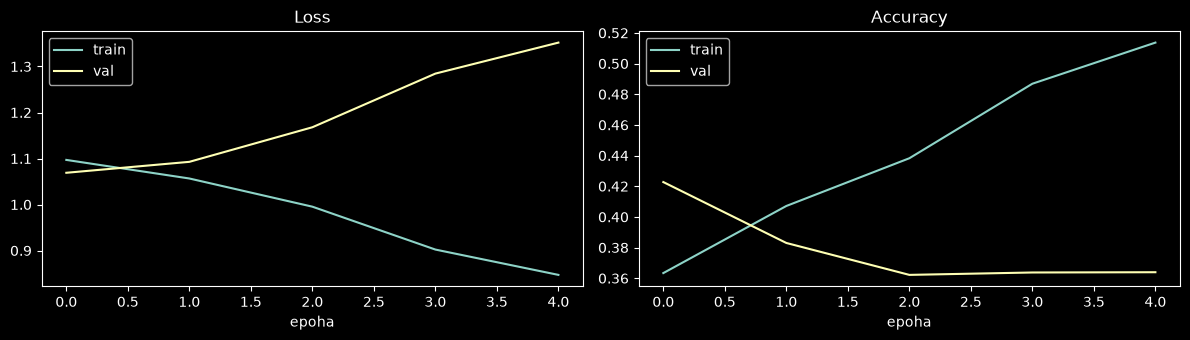

In [220]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoha"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoha"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Evaluacija klasifikacije (3 klase)

Napomena: sa 3 klase i neuravnoteženim udelima, “accuracy” je manje važan od toga **koliko često signal “long” zaista pogađa TP** — to je u sekciji 9.

In [221]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve, auc, balanced_accuracy_score)

proba_train = model.predict(X_train, batch_size=1024, verbose=0)
proba_val   = model.predict(X_val,   batch_size=1024, verbose=0)
proba_test  = model.predict(X_test,  batch_size=1024, verbose=0)
pred_train, pred_test = proba_train.argmax(1), proba_test.argmax(1)

naive_test = np.bincount(y_test, minlength=3).max() / len(y_test)
print("****Train Results****")
print("Accuracy: {:.4%} | balanced: {:.4%}".format(accuracy_score(y_train, pred_train), balanced_accuracy_score(y_train, pred_train)))
print("****Test Results****")
print("Accuracy: {:.4%} | balanced: {:.4%}".format(accuracy_score(y_test, pred_test), balanced_accuracy_score(y_test, pred_test)))
print("Naivna osnova (uvek najcesca klasa): {:.4%}".format(naive_test))

****Train Results****
Accuracy: 42.7439% | balanced: 44.5521%
****Test Results****
Accuracy: 48.4910% | balanced: 34.2299%
Naivna osnova (uvek najcesca klasa): 54.1422%


### Matrica konfuzije

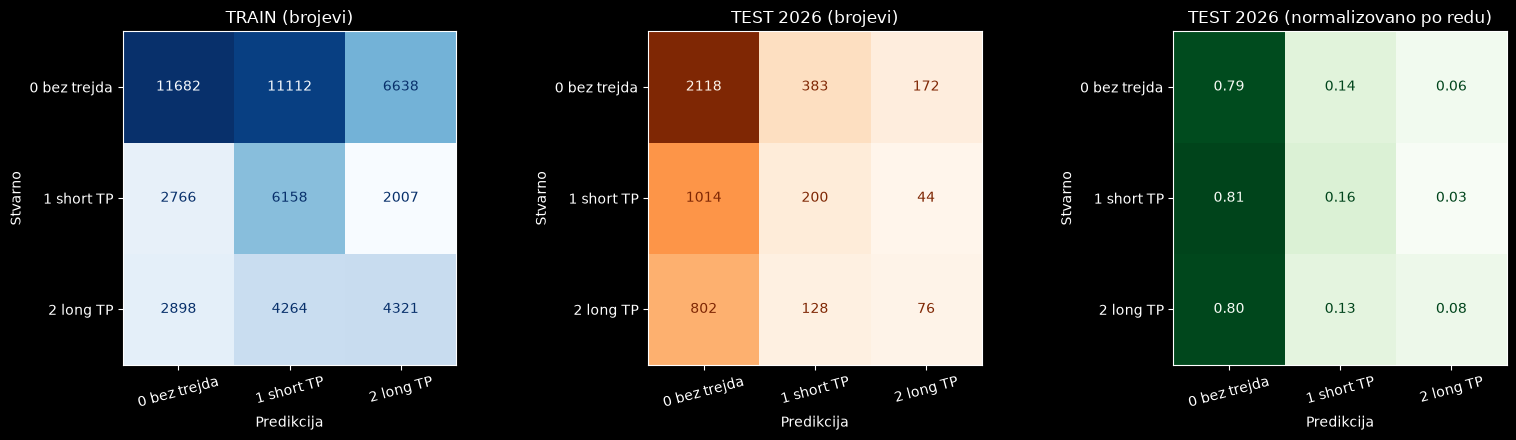

In [222]:
lbl = ["0 bez trejda", "1 short TP", "2 long TP"]
cm_train = confusion_matrix(y_train, pred_train, labels=[0, 1, 2])
cm_test  = confusion_matrix(y_test,  pred_test,  labels=[0, 1, 2])
print("Matrica konfuzije — TRAIN\n", cm_train)
print("Matrica konfuzije — TEST\n", cm_test)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(cm_train, display_labels=lbl).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("TRAIN (brojevi)")
ConfusionMatrixDisplay(cm_test, display_labels=lbl).plot(ax=ax[1], cmap="Oranges", colorbar=False)
ax[1].set_title("TEST 2026 (brojevi)")
cmn = cm_test / cm_test.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(np.round(cmn, 2), display_labels=lbl).plot(ax=ax[2], cmap="Greens", colorbar=False, values_format=".2f")
ax[2].set_title("TEST 2026 (normalizovano po redu)")
for a in ax:
    a.set_xlabel("Predikcija"); a.set_ylabel("Stvarno"); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

In [223]:
print("===== TRAIN =====\n", classification_report(y_train, pred_train, target_names=lbl, zero_division=0))
print("===== TEST =====\n",  classification_report(y_test,  pred_test,  target_names=lbl, zero_division=0))

===== TRAIN =====
               precision    recall  f1-score   support

0 bez trejda       0.67      0.40      0.50     29432
  1 short TP       0.29      0.56      0.38     10931
   2 long TP       0.33      0.38      0.35     11483

    accuracy                           0.43     51846
   macro avg       0.43      0.45      0.41     51846
weighted avg       0.52      0.43      0.44     51846

===== TEST =====
               precision    recall  f1-score   support

0 bez trejda       0.54      0.79      0.64      2673
  1 short TP       0.28      0.16      0.20      1258
   2 long TP       0.26      0.08      0.12      1006

    accuracy                           0.48      4937
   macro avg       0.36      0.34      0.32      4937
weighted avg       0.42      0.48      0.42      4937



In [224]:
# ROC kriva, jedna-protiv-ostalih (kao u referentnom notebook-u)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
aucs = {}
for c, col in zip((0, 1, 2), ("#888780", "#C0392B", "#1D9E75")):
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), proba_test[:, c])
    aucs[lbl[c]] = auc(fpr, tpr)
    ax[0].plot(fpr, tpr, color=col, label=f"{lbl[c]} (AUC={aucs[lbl[c]]:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.6)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC — jedna protiv ostalih (test)"); ax[0].legend(loc="lower right")

ax[1].hist(proba_test[y_test == 2, 2], bins=30, alpha=0.6, color="#1D9E75", label="P(long TP) kad long stvarno pogadja TP")
ax[1].hist(proba_test[y_test != 2, 2], bins=30, alpha=0.6, color="#888780", label="P(long TP) u ostalim slucajevima")
ax[1].set_title("Raspodela P(long TP) po stvarnoj klasi (test)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(aucs, index=["AUC"]).T.round(4)

,AUC
0 bez trejda,0.4998
1 short TP,0.5630
2 long TP,0.5490


## 9. Signali i backtest trejdova 1:2

* **LONG** ako je `P(klasa 2)` iznad praga i veća od `P(klasa 1)`; **SHORT** analogno za klasu 1; inače nema trejda
* pragovi = **80. percentil verovatnoća na validaciji** (ne gleda se test)
* jedan trejd u isto vreme: dok je trejd otvoren, novi signali se preskaču
* trošak: spread ${SPREAD} po trejdu, preračunat u R

In [225]:
def make_signals(proba, thr_long, thr_short):
    sig = np.zeros(len(proba), dtype=int)
    sig[(proba[:, 2] >= thr_long) & (proba[:, 2] > proba[:, 1])] = 1
    sig[(proba[:, 1] >= thr_short) & (proba[:, 1] > proba[:, 2])] = -1
    return sig

def run_rr_backtest(sig, lab, gold_index, spread=SPREAD_USD):
    # sig: Series (index = vreme odluke, vrednosti 1 / -1 / 0). Trejd se otvara na sledecoj svecu.
    pos = gold_index.get_indexer(sig.index)
    rows, busy = [], -1
    for tm, s, p in zip(sig.index, sig.values, pos):
        if s == 0 or p < busy:                 # nema signala ili je trejd jos otvoren
            continue
        side = "long" if s == 1 else "short"
        res, R = float(lab.at[tm, f"{side}_res"]), float(lab.at[tm, "R"])
        rows.append((tm, side, res, res - spread / R))
        busy = int(lab.at[tm, f"{side}_exit"])
    return pd.DataFrame(rows, columns=["time", "side", "R_gross", "R_net"]).set_index("time")

def rr_stats(tr, rr=RR, risk_pct=RISK_PCT):
    if tr.empty:
        return {"trejdova": 0}
    eq = tr["R_net"].cumsum()
    wins, losses = tr["R_net"][tr["R_net"] > 0].sum(), -tr["R_net"][tr["R_net"] < 0].sum()
    tp = tr["R_gross"] >= rr - 1e-9
    sl = tr["R_gross"] <= -1 + 1e-9
    return {
        "trejdova": len(tr),
        "long / short": f"{(tr['side'] == 'long').sum()} / {(tr['side'] == 'short').sum()}",
        "TP pogodjen": f"{tp.mean():.1%}",
        "SL pogodjen": f"{sl.mean():.1%}",
        "istek vremena": f"{(~tp & ~sl).mean():.1%}",
        "prosek R po trejdu (neto)": round(tr["R_net"].mean(), 3),
        "ukupno R (neto)": round(tr["R_net"].sum(), 1),
        "profit factor": round(wins / losses, 2) if losses > 0 else np.nan,
        "max drawdown (R)": round((eq - eq.cummax()).min(), 1),
        f"prinos pri {risk_pct:g}% rizika": f"{(1 + risk_pct / 100 * tr['R_net']).prod() - 1:.1%}",
    }

Q = 0.80
thr_long  = np.quantile(proba_val[:, 2], Q)
thr_short = np.quantile(proba_val[:, 1], Q)
print(f"Pragovi iz validacije (percentil {Q:.0%}):  LONG P2 >= {thr_long:.4f}  |  SHORT P1 >= {thr_short:.4f}")

sig_test = make_signals(proba_test, thr_long, thr_short)
sig_s = pd.Series(sig_test, index=test_index)
print(sig_s.map({1: "LONG", -1: "SHORT", 0: "bez trejda"}).value_counts())

# koliko cesto signal zaista pogadja TP (win rate signala, bez obzira na preklapanje trejdova)
long_sig, short_sig = sig_test == 1, sig_test == -1
base_long, base_short = (y_test == 2).mean(), (y_test == 1).mean()
print(f"\nLONG signali : win rate {(y_test[long_sig] == 2).mean():.1%}  (osnova svih sveca: {base_long:.1%}, break-even {1 / (1 + RR):.1%})")
print(f"SHORT signali: win rate {(y_test[short_sig] == 1).mean():.1%}  (osnova svih sveca: {base_short:.1%}, break-even {1 / (1 + RR):.1%})")

Pragovi iz validacije (percentil 80%):  LONG P2 >= 0.3518  |  SHORT P1 >= 0.3718
bez trejda    4131
SHORT          507
LONG           299
Name: count, dtype: int64

LONG signali : win rate 28.4%  (osnova svih sveca: 20.4%, break-even 25.0%)
SHORT signali: win rate 28.0%  (osnova svih sveca: 25.5%, break-even 25.0%)


In [226]:
# matrica konfuzije: signal vs ono sto se stvarno desilo (samo kad je bilo signala)
m = sig_test != 0
pred_sig = np.where(sig_test[m] == 1, 2, 1)
cm_sig = confusion_matrix(y_test[m], pred_sig, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5.2, 4.5))
ConfusionMatrixDisplay(cm_sig, display_labels=lbl).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_xlabel("Signal (1 = SHORT, 2 = LONG)"); ax.set_ylabel("Stvarni ishod"); ax.set_title("Samo kad je bilo signala (test)")
ax.tick_params(axis="x", rotation=15); plt.tight_layout(); plt.show()
print(cm_sig)

[[  0 276 175]
 [  0 142  39]
 [  0  89  85]]


In [227]:
gold_index = gold.index
tr_lstm   = run_rr_backtest(sig_s, lab, gold_index)
tr_long   = run_rr_backtest(pd.Series(1,  index=test_index), lab, gold_index)    # osnova: uvek long kad je flat
tr_short  = run_rr_backtest(pd.Series(-1, index=test_index), lab, gold_index)    # osnova: uvek short kad je flat

stats_df = pd.DataFrame({"LSTM signali": rr_stats(tr_lstm),
                         "Osnova: uvek LONG": rr_stats(tr_long),
                         "Osnova: uvek SHORT": rr_stats(tr_short)})
print(f"TEST 2026 — trejdovi 1:{RR:.0f} (SL = {SL_ATR_MULT} x ATR14, max {HORIZON} sveca, spread ${SPREAD_USD})")
stats_df

,LSTM signali,Osnova: uvek LONG,Osnova: uvek SHORT
trejdova,169,652,637
long / short,68 / 101,652 / 0,0 / 637
TP pogodjen,32.0%,19.6%,23.2%
SL pogodjen,60.9%,73.3%,70.2%
istek vremena,7.1%,7.1%,6.6%
prosek R po trejdu (neto),0.433,-0.083,0.048
ukupno R (neto),73.2,-54.3,30.8
profit factor,1.7,0.89,1.07
max drawdown (R),-14.7,-92.3,-37.3
prinos pri 1% rizika,101.7%,-46.6%,24.1%


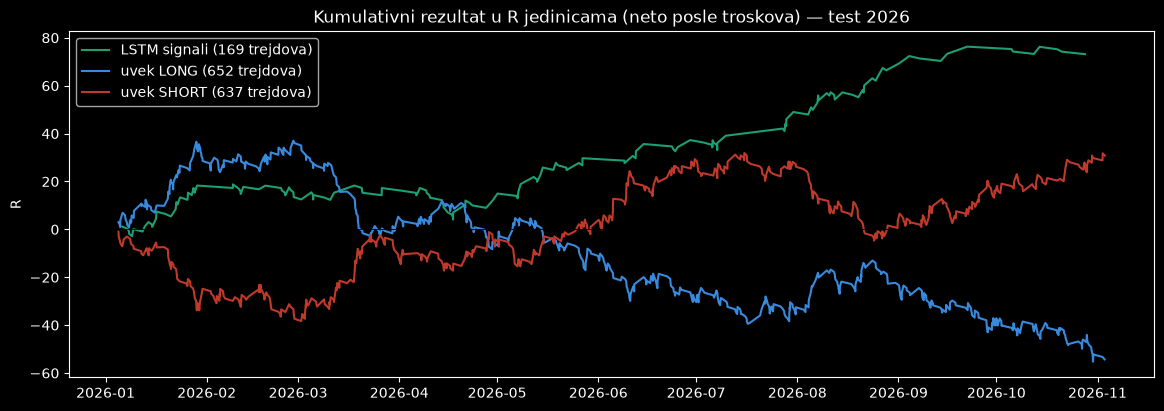

In [228]:
plt.figure(figsize=(14, 4.5))
for tr, name, col in ((tr_lstm, "LSTM signali", "#1D9E75"), (tr_long, "uvek LONG", "#378ADD"), (tr_short, "uvek SHORT", "#C0392B")):
    if len(tr):
        plt.plot(tr.index, tr["R_net"].cumsum(), label=f"{name} ({len(tr)} trejdova)", color=col)
plt.axhline(0, color="k", lw=0.6)
plt.title("Kumulativni rezultat u R jedinicama (neto posle troskova) — test 2026")
plt.ylabel("R"); plt.legend(); plt.show()

In [229]:
# Osetljivost na prag — SAMO INFORMATIVNO (prag u glavnom rezultatu ostaje fiksan iz validacije)
rows = []
for q in (0.50, 0.60, 0.70, 0.80, 0.90, 0.95):
    tl, ts = np.quantile(proba_val[:, 2], q), np.quantile(proba_val[:, 1], q)
    out = {"percentil": q}
    for nm, proba, idx in (("val", proba_val, val_index), ("test", proba_test, test_index)):
        tr = run_rr_backtest(pd.Series(make_signals(proba, tl, ts), index=idx), lab, gold_index)
        out[f"{nm}: trejdova"] = len(tr)
        out[f"{nm}: R/trejd"] = round(tr["R_net"].mean(), 3) if len(tr) else np.nan
    rows.append(out)
pd.DataFrame(rows).set_index("percentil")

,val: trejdova,val: R/trejd,test: trejdova,test: R/trejd
percentil,,,,
0.50,739,0.040,475,0.158
0.60,689,-0.008,400,0.226
0.70,615,-0.035,287,0.301
0.80,455,0.050,169,0.433
0.90,253,0.082,79,0.508
0.95,148,-0.065,31,0.356


## 10. Poređenje sa stablima odluke

Isti feature-i i ista podela, 3 klase (kao XGBoost u referentnom notebook-u; ovde `HistGradientBoostingClassifier`).
Ista pravila za signale i isti backtest 1:2.

In [230]:
from sklearn.ensemble import HistGradientBoostingClassifier

Xt_train, Xt_val, Xt_test = (data_scaled[end_idx][p] for p in (fit_pos, val_pos, te_pos))
trees = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, l2_regularization=1.0,
                                       early_stopping=False, class_weight="balanced", random_state=SEED)
trees.fit(Xt_train, y_train)
tp_train, tp_val, tp_test = (trees.predict_proba(X) for X in (Xt_train, Xt_val, Xt_test))
tpred_test = tp_test.argmax(1)

print("****Stabla odluke — Test****  Accuracy: {:.4%} | balanced: {:.4%}".format(
    accuracy_score(y_test, tpred_test), balanced_accuracy_score(y_test, tpred_test)))
cm_tree = confusion_matrix(y_test, tpred_test, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5.2, 4.5))
ConfusionMatrixDisplay(cm_tree, display_labels=lbl).plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_title("Stabla odluke — TEST 2026"); ax.set_xlabel("Predikcija"); ax.set_ylabel("Stvarno")
ax.tick_params(axis="x", rotation=15); plt.tight_layout(); plt.show()
print(classification_report(y_test, tpred_test, target_names=lbl, zero_division=0))

              precision    recall  f1-score   support

0 bez trejda       0.58      0.52      0.55      2673
  1 short TP       0.29      0.31      0.30      1258
   2 long TP       0.20      0.23      0.22      1006

    accuracy                           0.41      4937
   macro avg       0.36      0.36      0.35      4937
weighted avg       0.43      0.41      0.42      4937



In [231]:
tl_t, ts_t = np.quantile(tp_val[:, 2], Q), np.quantile(tp_val[:, 1], Q)
sig_tree = pd.Series(make_signals(tp_test, tl_t, ts_t), index=test_index)
tr_tree = run_rr_backtest(sig_tree, lab, gold_index)

# ansambl: prosek verovatnoca LSTM + stabla
p_ens_val, p_ens_test = (proba_val + tp_val) / 2, (proba_test + tp_test) / 2
sig_ens = pd.Series(make_signals(p_ens_test, np.quantile(p_ens_val[:, 2], Q), np.quantile(p_ens_val[:, 1], Q)), index=test_index)
tr_ens = run_rr_backtest(sig_ens, lab, gold_index)

summary = pd.DataFrame({"LSTM": rr_stats(tr_lstm), "Stabla odluke": rr_stats(tr_tree), "Ansambl": rr_stats(tr_ens),
                        "Uvek LONG": rr_stats(tr_long), "Uvek SHORT": rr_stats(tr_short)})
print("Slaganje LSTM i stabala u predikciji klase: {:.1%}".format((pred_test == tpred_test).mean()))
summary

,LSTM,Stabla odluke,Ansambl,Uvek LONG,Uvek SHORT
trejdova,169,359,249,652,637
long / short,68 / 101,246 / 113,127 / 122,652 / 0,0 / 637
TP pogodjen,32.0%,22.8%,26.1%,19.6%,23.2%
SL pogodjen,60.9%,70.8%,69.5%,73.3%,70.2%
istek vremena,7.1%,6.4%,4.4%,7.1%,6.6%
prosek R po trejdu (neto),0.433,0.023,0.116,-0.083,0.048
ukupno R (neto),73.2,8.4,29.0,-54.3,30.8
profit factor,1.7,1.03,1.17,0.89,1.07
max drawdown (R),-14.7,-46.6,-20.5,-92.3,-37.3
prinos pri 1% rizika,101.7%,3.4%,28.6%,-46.6%,24.1%


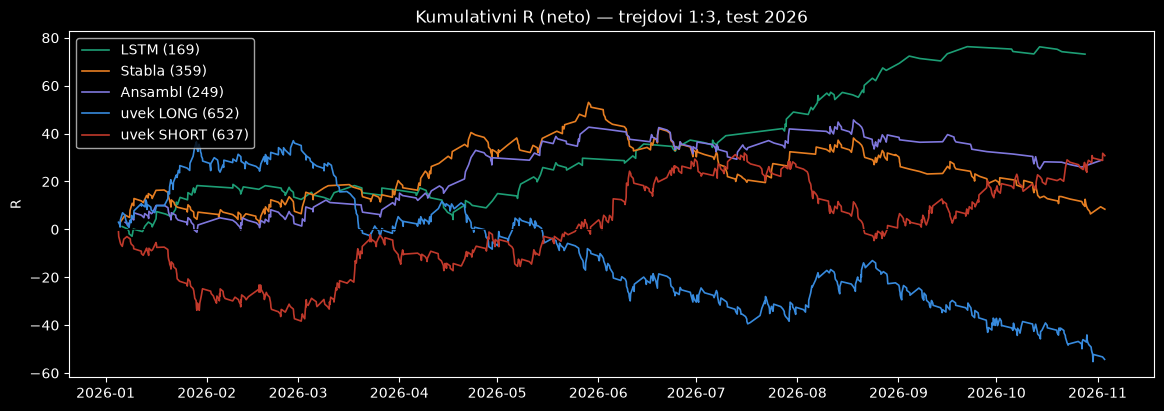

In [232]:
plt.figure(figsize=(14, 4.5))
for tr, name, col in ((tr_lstm, "LSTM", "#1D9E75"), (tr_tree, "Stabla", "#E67E22"), (tr_ens, "Ansambl", "#7F77DD"),
                      (tr_long, "uvek LONG", "#378ADD"), (tr_short, "uvek SHORT", "#C0392B")):
    if len(tr):
        plt.plot(tr.index, tr["R_net"].cumsum(), label=f"{name} ({len(tr)})", color=col, lw=1.2)
plt.axhline(0, color="k", lw=0.6)
plt.title(f"Kumulativni R (neto) — trejdovi 1:{RR:.0f}, test 2026"); plt.ylabel("R"); plt.legend(); plt.show()

## 11. Smer trenda v2: pomeraj ±250 pipsa **+ potvrda EMA 200**

<div style="background:#FFF3CD;border-left:6px solid #F0AD4E;padding:12px 16px;border-radius:4px;color:#412402">
<b>⚙️ OVDE SE PODEŠAVA</b> — parametri su u <b>prvoj ćeliji notebook-a</b>, u bloku sa zvezdicama <code>★ TREND ★</code>:<br>
<code>TREND_PIPS</code> &nbsp;|&nbsp; <code>PIP_SIZE_USD</code> &nbsp;|&nbsp; <code>TREND_LOOKBACK</code> &nbsp;|&nbsp; <code>TREND_EMA_LEN</code> &nbsp;|&nbsp;
<code>USE_TREND_FILTER</code> &nbsp;|&nbsp; <code>AUTO_SELECT_TREND</code> &nbsp;|&nbsp; <code>META_QUANTILE</code>
</div>

Pravilo (gleda samo unazad, bez curenja podataka):

* cena u poslednjih `TREND_LOOKBACK` sveća porasla ≥ `TREND_PIPS` **i** zatvaranje je iznad EMA(`TREND_EMA_LEN`) → **LONG**
* pala ≥ `TREND_PIPS` **i** zatvaranje je ispod EMA → **SHORT**
* inače → **NEUTRALAN** (nema trejda)

Ako je `AUTO_SELECT_TREND = True`, parametri se biraju iz mreže kandidata **isključivo na train godinama 2016–2025**
(prvo po udelu godina sa pozitivnim rezultatom, pa po prosečnom R po trejdu). Test 2026 se **ne koristi** pri izboru.

In [233]:
import itertools

def trend_state_v2(close, lookback, pips, ema_len):
    mv = (close - close.shift(lookback)) / PIP_SIZE_USD
    t = pd.Series(0, index=close.index)
    t[mv >= pips] = 1
    t[mv <= -pips] = -1
    if ema_len:
        ema = close.ewm(span=ema_len, adjust=False).mean()
        t[(t == 1) & (close < ema)] = 0
        t[(t == -1) & (close > ema)] = 0
    return t

GRID_LB   = {"1h": [12, 24, 48, 96], "1d": [3, 5, 10, 20]}[TIMEFRAME]
GRID_PIPS = [150, 250, 400]
GRID_EMA  = [0, 50, 200]
train_idx_all = data.index[train_mask]

def eval_trend(lookback, pips, ema_len, idx):
    t = trend_state_v2(gold["Close"], lookback, pips, ema_len).reindex(data.index).fillna(0).astype(int)
    return t, run_rr_backtest(pd.Series(t.reindex(idx).values, index=idx), lab, gold_index)

rows = []
for lb, pips, ema_len in itertools.product(GRID_LB, GRID_PIPS, GRID_EMA):
    _, tr = eval_trend(lb, pips, ema_len, train_idx_all)
    if len(tr) < MIN_TREND_TRADES:
        continue
    by_year = tr["R_net"].groupby(tr.index.year).mean()
    rows.append(dict(lookback=lb, pips=pips, ema=ema_len, trades=len(tr), R_per_trade=tr["R_net"].mean(),
                     years_positive=int((by_year > 0).sum()), years=len(by_year), worst_year=by_year.min()))
grid_df = pd.DataFrame(rows)
grid_df["pos_share"] = grid_df["years_positive"] / grid_df["years"]
grid_df = grid_df.sort_values(["pos_share", "R_per_trade"], ascending=False).reset_index(drop=True)

if AUTO_SELECT_TREND and len(grid_df):
    best = grid_df.iloc[0]
    TREND_LOOKBACK, TREND_PIPS, TREND_EMA_LEN = int(best["lookback"]), int(best["pips"]), int(best["ema"])
    print("AUTO odabrano (samo na train 2016-2025):")
else:
    print("RUCNE vrednosti iz prve celije:")
print(f"   TREND_LOOKBACK = {TREND_LOOKBACK} sveca | TREND_PIPS = {TREND_PIPS} | TREND_EMA_LEN = {TREND_EMA_LEN}")
print(f"   Kandidata u mrezi: {len(grid_df)} (min {MIN_TREND_TRADES} trejdova) — gornjih 10:")
grid_df.head(10).round(3)

,lookback,pips,ema,trades,R_per_trade,years_positive,years,worst_year,pos_share
0,12,250,200,799,0.081,7,11,-1.016,0.636
1,12,250,0,969,0.046,7,11,-1.014,0.636
2,12,250,50,932,0.038,7,11,-1.014,0.636
3,24,400,200,507,0.104,5,9,-1.017,0.556
4,24,400,50,575,0.084,5,9,-1.017,0.556
5,24,400,0,581,0.073,5,9,-1.017,0.556
6,48,400,0,1069,0.066,5,9,-1.017,0.556
7,48,400,200,1011,0.051,5,9,-1.017,0.556
8,48,400,50,1048,0.031,5,9,-1.017,0.556
9,12,150,200,1735,0.048,6,11,-1.016,0.545


In [234]:
trend_move_pips = (gold["Close"] - gold["Close"].shift(TREND_LOOKBACK)) / PIP_SIZE_USD
trend   = trend_state_v2(gold["Close"], TREND_LOOKBACK, TREND_PIPS, TREND_EMA_LEN)    # +1 LONG, -1 SHORT, 0 NEUTRALAN
trend_d = trend.reindex(data.index).fillna(0).astype(int)

print(f"TREND: pomeraj >= +{TREND_PIPS} pipsa (${TREND_PIPS * PIP_SIZE_USD:.2f}) u {TREND_LOOKBACK} sveca i cena iznad EMA{TREND_EMA_LEN} = LONG | "
      f"<= -{TREND_PIPS} pipsa i ispod EMA = SHORT | inace NEUTRALAN   (1 pip = ${PIP_SIZE_USD})")

N = 400 if TIMEFRAME == "1h" else len(test_index)
idx = test_index[:N]
px, tr_ = gold["Close"].reindex(idx), trend_d.reindex(idx)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(px.index, px.values, color="black", lw=0.8)
lo, hi = px.min(), px.max()
ax.fill_between(px.index, lo, hi, where=(tr_.values == 1),  color="#1D9E75", alpha=0.20, label="trend LONG")
ax.fill_between(px.index, lo, hi, where=(tr_.values == -1), color="#C0392B", alpha=0.20, label="trend SHORT")
ax.set_title("Trend v2 (zeleno = LONG, crveno = SHORT, bez boje = neutralan)"); ax.legend(loc="upper left"); plt.show()

dist = pd.DataFrame({"train 2016-2025": trend_d[train_mask].value_counts(normalize=True),
                     "test 2026": trend_d[~train_mask].value_counts(normalize=True)}
                    ).rename(index={1: "LONG", -1: "SHORT", 0: "NEUTRALAN"}).fillna(0).round(3)
dist

,train 2016-2025,test 2026
SHORT,0.022,0.218
NEUTRALAN,0.945,0.604
LONG,0.032,0.178


In [235]:
# (1) Samostalno pravilo trenda (1:2) — bez ucenja, pa se proverava i na TRAIN (mnogo trejdova) i na TEST
def trend_signals(idx):
    return pd.Series(trend_d.reindex(idx).values, index=idx)

tr_rule_train = run_rr_backtest(trend_signals(train_idx_all), lab, gold_index)
tr_rule_test  = run_rr_backtest(trend_signals(test_index),   lab, gold_index)
print(f"Pravilo trenda v2, trejdovi 1:{RR:.0f} (break-even win rate {1 / (1 + RR):.1%})")
by_year = tr_rule_train["R_net"].groupby(tr_rule_train.index.year).agg(["count", "mean"]).round(3)
by_year.columns = ["trejdova", "R po trejdu"]
print("Po godinama (train):", by_year["R po trejdu"].to_dict())
pd.DataFrame({"Trend v2 — TRAIN 2016-2025": rr_stats(tr_rule_train), "Trend v2 — TEST 2026": rr_stats(tr_rule_test)})

,Trend v2 — TRAIN 2016-2025,Trend v2 — TEST 2026
trejdova,799,378
long / short,445 / 354,164 / 214
TP pogodjen,23.7%,25.7%
SL pogodjen,67.0%,66.4%
istek vremena,9.4%,7.9%
prosek R po trejdu (neto),0.081,0.155
ukupno R (neto),64.5,58.5
profit factor,1.12,1.23
max drawdown (R),-22.0,-21.8
prinos pri 1% rizika,69.9%,69.5%


In [236]:
# (2) Trend kao filter za 3-klasni LSTM i stabla (iz sekcija 8-10)
def apply_trend_filter(sig, trend_vals):
    out = np.array(sig, copy=True)
    out[(out == 1)  & (trend_vals != 1)]  = 0
    out[(out == -1) & (trend_vals != -1)] = 0
    return out

trend_test = trend_d.reindex(test_index).values
if USE_TREND_FILTER:
    sig_lstm_f = apply_trend_filter(sig_test, trend_test)
    sig_tree_f = apply_trend_filter(sig_tree.values, trend_test)
else:
    sig_lstm_f, sig_tree_f = sig_test.copy(), sig_tree.values.copy()
tr_lstm_f = run_rr_backtest(pd.Series(sig_lstm_f, index=test_index), lab, gold_index)
tr_tree_f = run_rr_backtest(pd.Series(sig_tree_f, index=test_index), lab, gold_index)
print(f"LSTM signala pre filtera: {(sig_test != 0).sum()} -> posle: {(sig_lstm_f != 0).sum()}")
pd.DataFrame({"Samo trend v2": rr_stats(tr_rule_test), "LSTM (bez filtera)": rr_stats(tr_lstm),
              "LSTM + trend filter": rr_stats(tr_lstm_f), "Stabla + trend filter": rr_stats(tr_tree_f),
              "Uvek LONG": rr_stats(tr_long), "Uvek SHORT": rr_stats(tr_short)})

,Samo trend v2,LSTM (bez filtera),LSTM + trend filter,Stabla + trend filter,Uvek LONG,Uvek SHORT
trejdova,378,169,44,46,652,637
long / short,164 / 214,68 / 101,31 / 13,36 / 10,652 / 0,0 / 637
TP pogodjen,25.7%,32.0%,36.4%,26.1%,19.6%,23.2%
SL pogodjen,66.4%,60.9%,54.5%,65.2%,73.3%,70.2%
istek vremena,7.9%,7.1%,9.1%,8.7%,7.1%,6.6%
prosek R po trejdu (neto),0.155,0.433,0.626,0.246,-0.083,0.048
ukupno R (neto),58.5,73.2,27.5,11.3,-54.3,30.8
profit factor,1.23,1.7,2.12,1.37,0.89,1.07
max drawdown (R),-21.8,-14.7,-4.2,-5.0,-92.3,-37.3
prinos pri 1% rizika,69.5%,101.7%,30.6%,11.2%,-46.6%,24.1%


## 12. Meta-model: trend bira SMER, model bira DA LI uzeti trejd

Umesto da mreža pogađa smer (što ne uspeva), **pravilo trenda određuje smer**, a sekundarni (meta) model odgovara na jedno pitanje:
*“Hoće li trejd u smeru trenda pogoditi TP (+2R) pre SL (−1R)?”* — i prihvata samo bolju polovinu setup-a
(`META_QUANTILE`, prag se računa na **validaciji**, ne na testu).

Treniraju se **stabla odluke** i **LSTM** (3 seed-a, sekvenca + kanal trenda), pa njihov prosek (ansambl).
Break-even win rate za 1:2 je 33.3%.

In [237]:
trend_vals  = trend_d.values                                           # poravnato sa data.index
move_scaled = np.clip(trend_move_pips.reindex(data.index).fillna(0).values / TREND_PIPS, -3, 3)

def meta_sets(pos):
    end = end_idx[pos]
    tr = trend_vals[end]
    keep = tr != 0                                                     # samo sveće sa aktivnim trendom
    pos, tr, end = pos[keep], tr[keep], end[keep]
    y = (((tr == 1) & (y_seq[pos] == 2)) | ((tr == -1) & (y_seq[pos] == 1))).astype(int)   # trejd u smeru trenda pogadja TP
    tab = np.c_[data_scaled[end], tr, move_scaled[end]].astype(np.float32)
    return dict(pos=pos, trend=tr, y=y, tab=tab, idx=t_seq[pos])

M_fit, M_val, M_test = meta_sets(fit_pos), meta_sets(val_pos), meta_sets(te_pos)
print(f"Break-even win rate: {1 / (1 + RR):.1%}")
for nm, M in (("fit", M_fit), ("val", M_val), ("test", M_test)):
    print(f"{nm:5s}: {len(M['y']):5d} trend-sveca | trejd u smeru trenda pogadja TP u {M['y'].mean():.1%}")

Break-even win rate: 25.0%
fit  :  1777 trend-sveca | trejd u smeru trenda pogadja TP u 22.9%
val  :  1378 trend-sveca | trejd u smeru trenda pogadja TP u 29.8%
test :  1956 trend-sveca | trejd u smeru trenda pogadja TP u 26.0%


In [238]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# --- meta stabla ---
meta_trees = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, max_depth=3, l2_regularization=2.0,
                                            min_samples_leaf=40, early_stopping=False, class_weight="balanced",
                                            random_state=SEED)
meta_trees.fit(M_fit["tab"], M_fit["y"])
p_tree = {nm: meta_trees.predict_proba(M["tab"])[:, 1] for nm, M in (("val", M_val), ("test", M_test))}

# --- meta LSTM (sekvenca + kanal trenda), prosek 3 seed-a ---
def meta_seq(M):
    w = windows[M["pos"]].astype(np.float32)
    ch = np.repeat(M["trend"][:, None, None].astype(np.float32), BACKCANDLES, axis=1)
    return np.concatenate([w, ch], axis=2)

S_fit, S_val, S_test = meta_seq(M_fit), meta_seq(M_val), meta_seq(M_test)
cw_m = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=M_fit["y"])))

def build_meta_lstm(units):
    inp = Input(shape=(BACKCANDLES, n_feat + 1))
    x = LSTM(units)(inp); x = Dropout(0.4)(x); x = Dense(16, activation="relu")(x); x = Dropout(0.3)(x)
    out = Dense(1, activation="sigmoid")(x)
    m = Model(inp, out); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return m

pl_val, pl_test = [], []
for s in range(3):
    tf.keras.utils.set_random_seed(SEED + s)
    mm = build_meta_lstm({"1h": 32, "1d": 16}[TIMEFRAME])
    mm.fit(S_fit, M_fit["y"], validation_data=(S_val, M_val["y"]), epochs=40,
           batch_size={"1h": 128, "1d": 32}[TIMEFRAME], class_weight=cw_m, verbose=0,
           callbacks=[EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
    pl_val.append(mm.predict(S_val, verbose=0).ravel()); pl_test.append(mm.predict(S_test, verbose=0).ravel())
p_lstm = {"val": np.mean(pl_val, axis=0), "test": np.mean(pl_test, axis=0)}
p_ens  = {k: (p_tree[k] + p_lstm[k]) / 2 for k in ("val", "test")}

def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan")
pd.DataFrame({"AUC val": [safe_auc(M_val["y"], p[ "val"]) for p in (p_tree, p_lstm, p_ens)],
              "AUC test": [safe_auc(M_test["y"], p["test"]) for p in (p_tree, p_lstm, p_ens)]},
             index=["Meta stabla", "Meta LSTM", "Meta ansambl"]).round(4)

,AUC val,AUC test
Meta stabla,0.5443,0.5392
Meta LSTM,0.5787,0.5714
Meta ansambl,0.5780,0.5597


In [239]:
def meta_signals(M, p, thr):
    s = np.zeros(len(p), dtype=int)
    take = p >= thr
    s[take] = M["trend"][take]                                         # smer = trend, ulaz samo ako je meta prob >= prag
    return s, take

variants = {"Meta: stabla": p_tree, "Meta: LSTM": p_lstm, "Meta: ansambl": p_ens}
res, trades = {}, {}
for name, p in variants.items():
    thr = np.quantile(p["val"], META_QUANTILE)                         # prag iz VALIDACIJE
    sig, take = meta_signals(M_test, p["test"], thr)
    full = pd.Series(sig, index=M_test["idx"]).reindex(test_index).fillna(0).astype(int)
    trades[name] = run_rr_backtest(full, lab, gold_index)
    res[name] = dict(thr=thr, take=take)
    w_all, w_sel = M_test["y"].mean(), M_test["y"][take].mean() if take.sum() else float("nan")
    print(f"{name:14s} prag {thr:.3f} | prihvaceno {take.sum()}/{len(take)} setup-a | win rate prihvacenih {w_sel:.1%} "
          f"(svih trend setup-a {w_all:.1%}, break-even {1 / (1 + RR):.1%})")

stats = {"Samo trend v2 (svi setup-i)": rr_stats(tr_rule_test)}
stats.update({k: rr_stats(v) for k, v in trades.items()})
stats["Uvek LONG"], stats["Uvek SHORT"] = rr_stats(tr_long), rr_stats(tr_short)
pd.DataFrame(stats)

,Samo trend v2 (svi setup-i),Meta: stabla,Meta: LSTM,Meta: ansambl,Uvek LONG,Uvek SHORT
trejdova,378,238,178,209,652,637
long / short,164 / 214,86 / 152,68 / 110,71 / 138,652 / 0,0 / 637
TP pogodjen,25.7%,25.6%,25.3%,24.9%,19.6%,23.2%
SL pogodjen,66.4%,67.2%,67.4%,68.4%,73.3%,70.2%
istek vremena,7.9%,7.1%,7.3%,6.7%,7.1%,6.6%
prosek R po trejdu (neto),0.155,0.138,0.136,0.111,-0.083,0.048
ukupno R (neto),58.5,32.9,24.3,23.1,-54.3,30.8
profit factor,1.23,1.2,1.2,1.16,0.89,1.07
max drawdown (R),-21.8,-22.8,-11.4,-16.5,-92.3,-37.3
prinos pri 1% rizika,69.5%,34.0%,24.1%,22.1%,-46.6%,24.1%


In [240]:
# matrica konfuzije meta odluke (ansambl): da li je setup prihvacen vs da li je trejd stvarno pogodio TP
take = res["Meta: ansambl"]["take"]
cm_meta = confusion_matrix(M_test["y"], take.astype(int), labels=[0, 1])
cmn_meta = cm_meta / np.maximum(cm_meta.sum(axis=1, keepdims=True), 1)
print("Matrica konfuzije (redovi = stvarno, kolone = odluka):\n", cm_meta)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ConfusionMatrixDisplay(cm_meta, display_labels=["odbijen", "prihvacen"]).plot(ax=ax[0], cmap="Purples", colorbar=False)
ax[0].set_title("Meta odluka (test, brojevi)"); ax[0].set_ylabel("Stvarno: 0 = SL/istek, 1 = TP"); ax[0].set_xlabel("Odluka")
ConfusionMatrixDisplay(np.round(cmn_meta, 2), display_labels=["odbijen", "prihvacen"]).plot(ax=ax[1], cmap="Greens", colorbar=False, values_format=".2f")
ax[1].set_title("normalizovano po redu"); ax[1].set_xlabel("Odluka")
if len(np.unique(M_test["y"])) > 1:
    for nm, p, col in (("stabla", p_tree, "#E67E22"), ("LSTM", p_lstm, "#1D9E75"), ("ansambl", p_ens, "#7F77DD")):
        fpr, tpr, _ = roc_curve(M_test["y"], p["test"]); ax[2].plot(fpr, tpr, color=col, label=f"{nm} (AUC {auc(fpr, tpr):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--", lw=0.6); ax[2].legend(); ax[2].set_title("ROC meta modela (test)")
    ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
plt.tight_layout(); plt.show()
print(classification_report(M_test["y"], take.astype(int), target_names=["odbijen", "prihvacen"], zero_division=0))

              precision    recall  f1-score   support

     odbijen       0.77      0.64      0.70      1448
   prihvacen       0.31      0.46      0.37       508

    accuracy                           0.59      1956
   macro avg       0.54      0.55      0.53      1956
weighted avg       0.65      0.59      0.61      1956



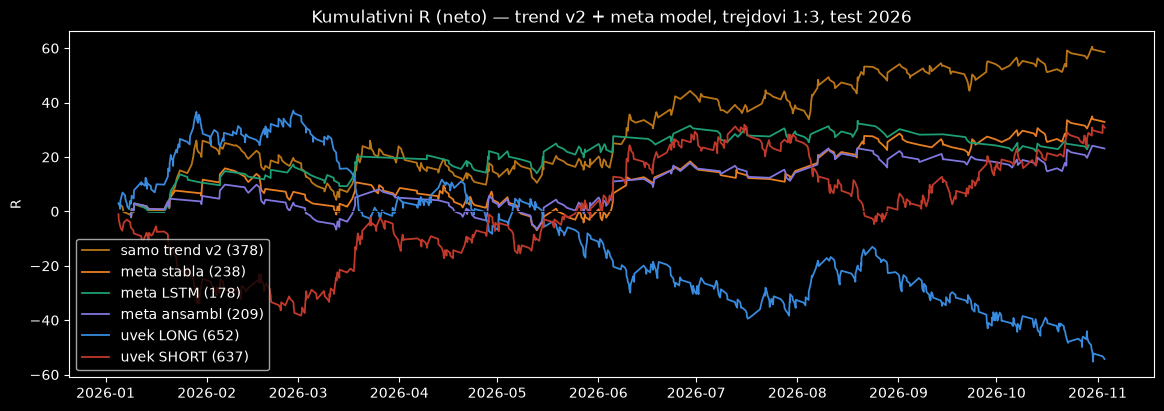

In [241]:
plt.figure(figsize=(14, 4.5))
curves = [(tr_rule_test, "samo trend v2", "#BA7517"), (trades["Meta: stabla"], "meta stabla", "#E67E22"),
          (trades["Meta: LSTM"], "meta LSTM", "#1D9E75"), (trades["Meta: ansambl"], "meta ansambl", "#7F77DD"),
          (tr_long, "uvek LONG", "#378ADD"), (tr_short, "uvek SHORT", "#C0392B")]
for tr, name, col in curves:
    if len(tr):
        plt.plot(tr.index, tr["R_net"].cumsum(), label=f"{name} ({len(tr)})", lw=1.3, color=col)
plt.axhline(0, color="k", lw=0.6)
plt.title(f"Kumulativni R (neto) — trend v2 + meta model, trejdovi 1:{RR:.0f}, test 2026"); plt.ylabel("R"); plt.legend(); plt.show()

In [242]:
# Poslednji signali (ansambl): smer = trend, ocena = verovatnoca da trejd pogodi TP
p_last = p_ens["test"]; thr_last = res["Meta: ansambl"]["thr"]
sig_table = pd.DataFrame({
    "trend": np.where(M_test["trend"] == 1, "LONG", "SHORT"),
    "meta_verovatnoca_TP": p_last.round(3),
    "score (0-100)": (p_last * 100).round(1),
    "odluka": np.where(p_last >= thr_last, np.where(M_test["trend"] == 1, "LONG", "SHORT"), "NEMA TREJDA"),
    "stvarno (TP pogodjen?)": np.where(M_test["y"] == 1, "da", "ne"),
}, index=M_test["idx"])
print(f"Prag odluke (iz validacije): meta verovatnoca >= {thr_last:.3f}")
sig_table.tail(15)

,trend,meta_verovatnoca_TP,score (0-100),odluka,stvarno (TP pogodjen?)
Date,,,,,
2026-10-30 14:00:00,SHORT,0.230,23.0,NEMA TREJDA,ne
2026-10-30 15:00:00,SHORT,0.165,16.5,NEMA TREJDA,ne
2026-10-30 16:00:00,SHORT,0.148,14.8,NEMA TREJDA,ne
2026-10-30 17:00:00,SHORT,0.142,14.2,NEMA TREJDA,ne
2026-10-30 18:00:00,SHORT,0.134,13.4,NEMA TREJDA,ne
2026-10-30 19:00:00,SHORT,0.134,13.4,NEMA TREJDA,ne
2026-10-30 20:00:00,SHORT,0.130,13.0,NEMA TREJDA,ne
2026-11-01 23:00:00,SHORT,0.217,21.7,NEMA TREJDA,ne
2026-11-02 00:00:00,SHORT,0.236,23.6,NEMA TREJDA,ne


In [243]:
# Osetljivost na META_QUANTILE — SAMO INFORMATIVNO (prag u glavnom rezultatu je fiksan u prvoj celiji)
rows = []
for q in (0.0, 0.3, 0.5, 0.7, 0.85):
    thr = np.quantile(p_ens["val"], q)
    out = {"META_QUANTILE": q}
    for nm, M, p in (("val", M_val, p_ens["val"]), ("test", M_test, p_ens["test"])):
        sig, tk = meta_signals(M, p, thr)
        tr = run_rr_backtest(pd.Series(sig, index=M["idx"]).reindex(M["idx"]).fillna(0).astype(int), lab, gold_index)
        out[f"{nm}: trejdova"] = len(tr)
        out[f"{nm}: R/trejd"] = round(tr["R_net"].mean(), 3) if len(tr) else np.nan
    rows.append(out)
pd.DataFrame(rows).set_index("META_QUANTILE")

,val: trejdova,val: R/trejd,test: trejdova,test: R/trejd
META_QUANTILE,,,,
0.00,298,0.122,379,0.152
0.30,236,0.183,283,0.081
0.50,176,0.280,209,0.111
0.70,109,0.376,124,0.184
0.85,60,0.801,48,0.286


## 13. Čuvanje modela

In [244]:
import joblib
out_dir = Path("rezultati_notebook_rr"); out_dir.mkdir(exist_ok=True)
model.save(out_dir / f"lstm_rr12_{TIMEFRAME}.keras")
joblib.dump({"scaler": scaler, "feature_cols": feature_cols, "backcandles": BACKCANDLES, "rr": RR,
             "sl_atr_mult": SL_ATR_MULT, "horizon": HORIZON, "trend": dict(pips=TREND_PIPS, lookback=TREND_LOOKBACK, ema=TREND_EMA_LEN, pip_size=PIP_SIZE_USD), "thr_long": float(thr_long), "thr_short": float(thr_short)},
            out_dir / f"lstm_rr12_{TIMEFRAME}_meta.joblib")
tr_lstm.to_csv(out_dir / f"trejdovi_lstm_{TIMEFRAME}_test.csv")
print("Sacuvano u:", out_dir.resolve())

Sacuvano u: /Users/djordjeradosavljevic/Downloads/fax/diplomski/code/rezultati_notebook_rr
